In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions_seattle/evaluation_results_5seeds_epsg:26910_4.csv")
results = results.drop(["dataset", "pred_root"], axis=1)
results.groupby(["model", "tag"]).mean().reset_index()[["model", "tag", "iou", "traversability_similarity"]].round(3)

,model,tag,iou,traversability_similarity
0,resnet18,base,0.438,0.386
1,resnet18,grpo,0.442,0.387
2,resnet18,step,0.459,0.404
3,swin_tiny,base,0.467,0.401
4,swin_tiny,grpo,0.485,0.415
5,swin_tiny,step,0.488,0.418
6,vit_small,base,0.453,0.382
7,vit_small,grpo,0.466,0.401


In [3]:
results.groupby(["model", "tag"]).std().reset_index()[["model", "tag", "iou", "avg_f1", "traversability_similarity"]].round(3)

,model,tag,iou,avg_f1,traversability_similarity
0,resnet18,base,0.003,0.004,0.005
1,resnet18,grpo,0.001,0.002,0.008
2,resnet18,step,0.002,0.003,0.004
3,swin_tiny,base,0.004,0.004,0.006
4,swin_tiny,grpo,0.002,0.002,0.004
5,tile2net,base,NaN,NaN,NaN
6,vit_small,base,0.003,0.002,0.005
7,vit_small,grpo,0.003,0.003,0.003


/tmp/ipykernel_262173/3610413494.py:4: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  results.tag[results.tag == 'base'] = 'TraversCNN'
/tmp/ipykernel_262173/3610413494.py:5: FutureWarning: ChainedAssignmentError: behaviour will change in pan

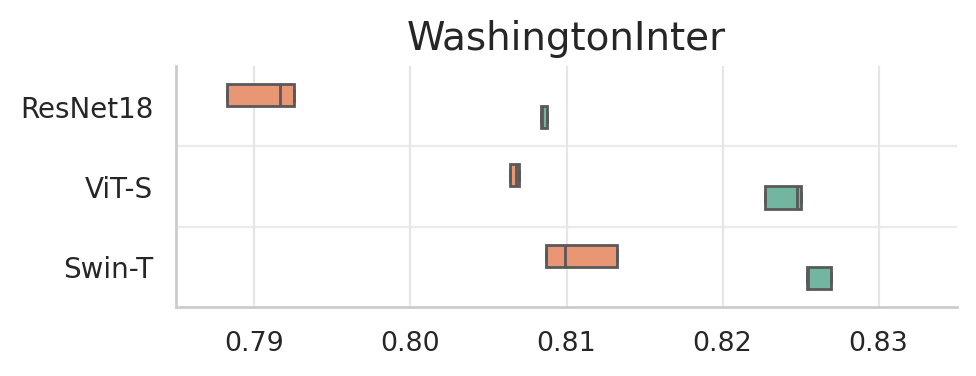

In [3]:
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions/evaluation_results_5seeds_epsg:26910_4.csv")
results = results.drop(["dataset", "pred_root"], axis=1)
results = results[results.model != "tile2net"]
results.tag[results.tag == 'base'] = 'TraversCNN'
results.tag[results.tag == 'grpo'] = 'TraversRL'

metric = "iou"
model_order = ["resnet18", "vit_small", "swin_tiny"]
pretty_model = {
    "resnet18": "ResNet18",
    "vit_small": "ViT-S",
    "swin_tiny": "Swin-T",
}

# --- style tuned for papers ---
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlepad": 6,
    "legend.frameon": False,
})

fig, ax = plt.subplots(figsize=(5, 2))  # compact for 1-column paper

# stable palette across figures
tags = list(results["tag"].unique())
palette = dict(zip(tags, sns.color_palette("colorblind", n_colors=len(tags))))

# --- choose ONE palette ---
# palette_list = sns.color_palette("Dark2", n_colors=len(tags))          # recommended for 2–4 tags
# palette_list = sns.color_palette("deep", n_colors=len(tags))
palette_list = sns.color_palette("Set2", n_colors=len(tags))
palette = dict(zip(tags[::-1], palette_list))

sns.boxplot(
    data=results,
    y="model", x=metric, hue="tag",
    order=model_order,
    palette=palette,
    width=0.55,
    linewidth=1.0,
    whis=(5, 95),          # more robust whiskers than default 1.5 IQR
    showfliers=False,
    ax=ax,
    legend=False
)

# subtle separators (lighter than your current)
for y in range(1, len(model_order)):
    ax.axhline(y - 0.5, color="0.92", linewidth=0.8, zorder=0)

ax.set_title("WashingtonInter", fontsize=14)
ax.set_xlabel("")
ax.set_ylabel("")  # cleaner; model names already on axis
ax.set_yticklabels([pretty_model.get(m, m) for m in model_order], fontsize=10)

# lighter grid, only on x (since x is numeric)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="0.9", linewidth=0.8)

# optional: consistent x-range for IoU
ax.set_xlim(0.785, 0.835)

fig.tight_layout()
# plt.savefig("visualizations/washingtoninter_iou.png", bbox_inches="tight", pad_inches=0.0, dpi=600)
plt.show()

/tmp/ipykernel_2589026/201178326.py:4: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  results.tag[results.tag == 'base'] = 'TraversCNN'
/tmp/ipykernel_2589026/201178326.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a

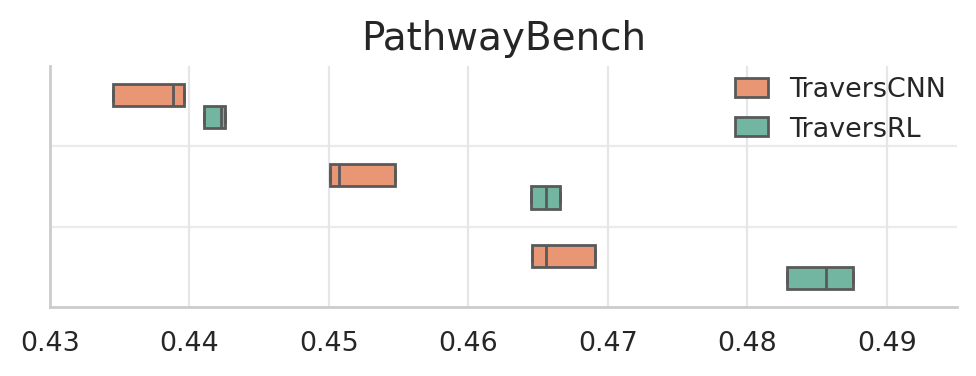

In [18]:
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions_seattle/evaluation_results_5seeds.csv")
results = results.drop(["dataset", "pred_root"], axis=1)
results = results[results.model != "tile2net"]
results.tag[results.tag == 'base'] = 'TraversCNN'
results.tag[results.tag == 'grpo'] = 'TraversRL'

metric = "iou"
model_order = ["resnet18", "vit_small", "swin_tiny"]
pretty_model = {
    "resnet18": "ResNet18",
    "vit_small": "ViT-S",
    "swin_tiny": "Swin-T",
}

# --- style tuned for papers ---
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlepad": 6,
    "legend.frameon": False,
})

fig, ax = plt.subplots(figsize=(5, 2))  # compact for 1-column paper

# stable palette across figures
tags = list(results["tag"].unique())
palette = dict(zip(tags, sns.color_palette("colorblind", n_colors=len(tags))))

# --- choose ONE palette ---
# palette_list = sns.color_palette("Dark2", n_colors=len(tags))          # recommended for 2–4 tags
# palette_list = sns.color_palette("deep", n_colors=len(tags))
palette_list = sns.color_palette("Set2", n_colors=len(tags))
palette = dict(zip(tags[::-1], palette_list))

sns.boxplot(
    data=results,
    y="model", x=metric, hue="tag",
    order=model_order,
    palette=palette,
    width=0.55,
    linewidth=1.0,
    whis=(5, 95),          # more robust whiskers than default 1.5 IQR
    showfliers=False,
    ax=ax
)

# subtle separators (lighter than your current)
for y in range(1, len(model_order)):
    ax.axhline(y - 0.5, color="0.92", linewidth=0.8, zorder=0)

ax.set_title("PathwayBench", fontsize=14)
ax.set_xlabel("")
ax.set_ylabel("")  # cleaner; model names already on axis
ax.set_yticklabels("")

# legend on top/right, compact
leg = ax.legend(
    title="",
    loc="upper right",
    #bbox_to_anchor=(1.0, 1.02),
    ncol=1,
    borderaxespad=0.0,
    handlelength=1.2,
    columnspacing=1.0
)

# lighter grid, only on x (since x is numeric)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="0.9", linewidth=0.8)

# optional: consistent x-range for IoU
ax.set_xlim(0.43, 0.495)

fig.tight_layout()
plt.savefig("visualizations/pathwaybench_iou.png", bbox_inches="tight", pad_inches=0.0, dpi=600)
plt.show()

In [8]:
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions/evaluation_results_5seeds_epsg:26910_4.csv")

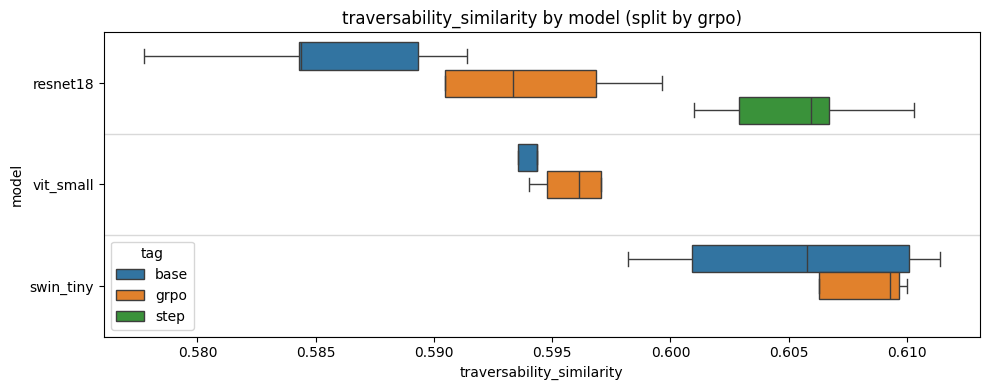

In [6]:
metric = "traversability_similarity"
plt.figure(figsize=(10, 4))
model_order = ["resnet18", "vit_small", "swin_tiny"]
ax = sns.boxplot(
    y="model", x=metric, hue="tag",
    data=results,
    order=model_order,
    showbox=True,
    showfliers=False
)
n_models = results["model"].nunique()
for y in range(1, n_models):
    ax.axhline(y - 0.5, color="0.85", linewidth=1, zorder=0)
ax.set_title(f"{metric} by model (split by grpo)")
plt.tight_layout()
plt.show()

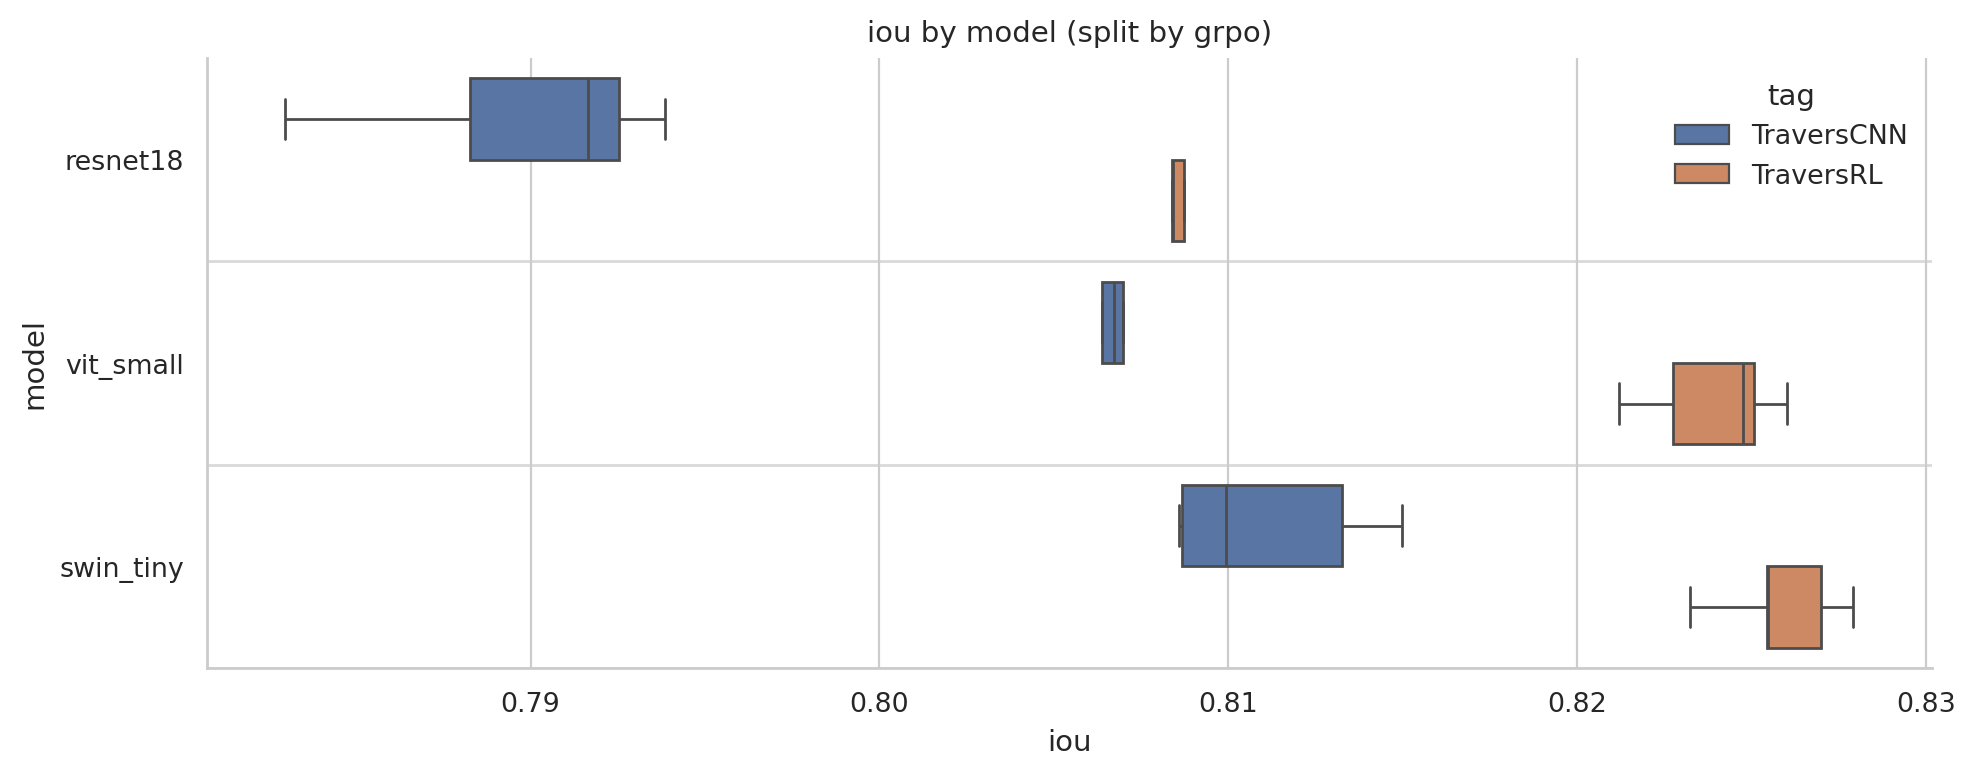

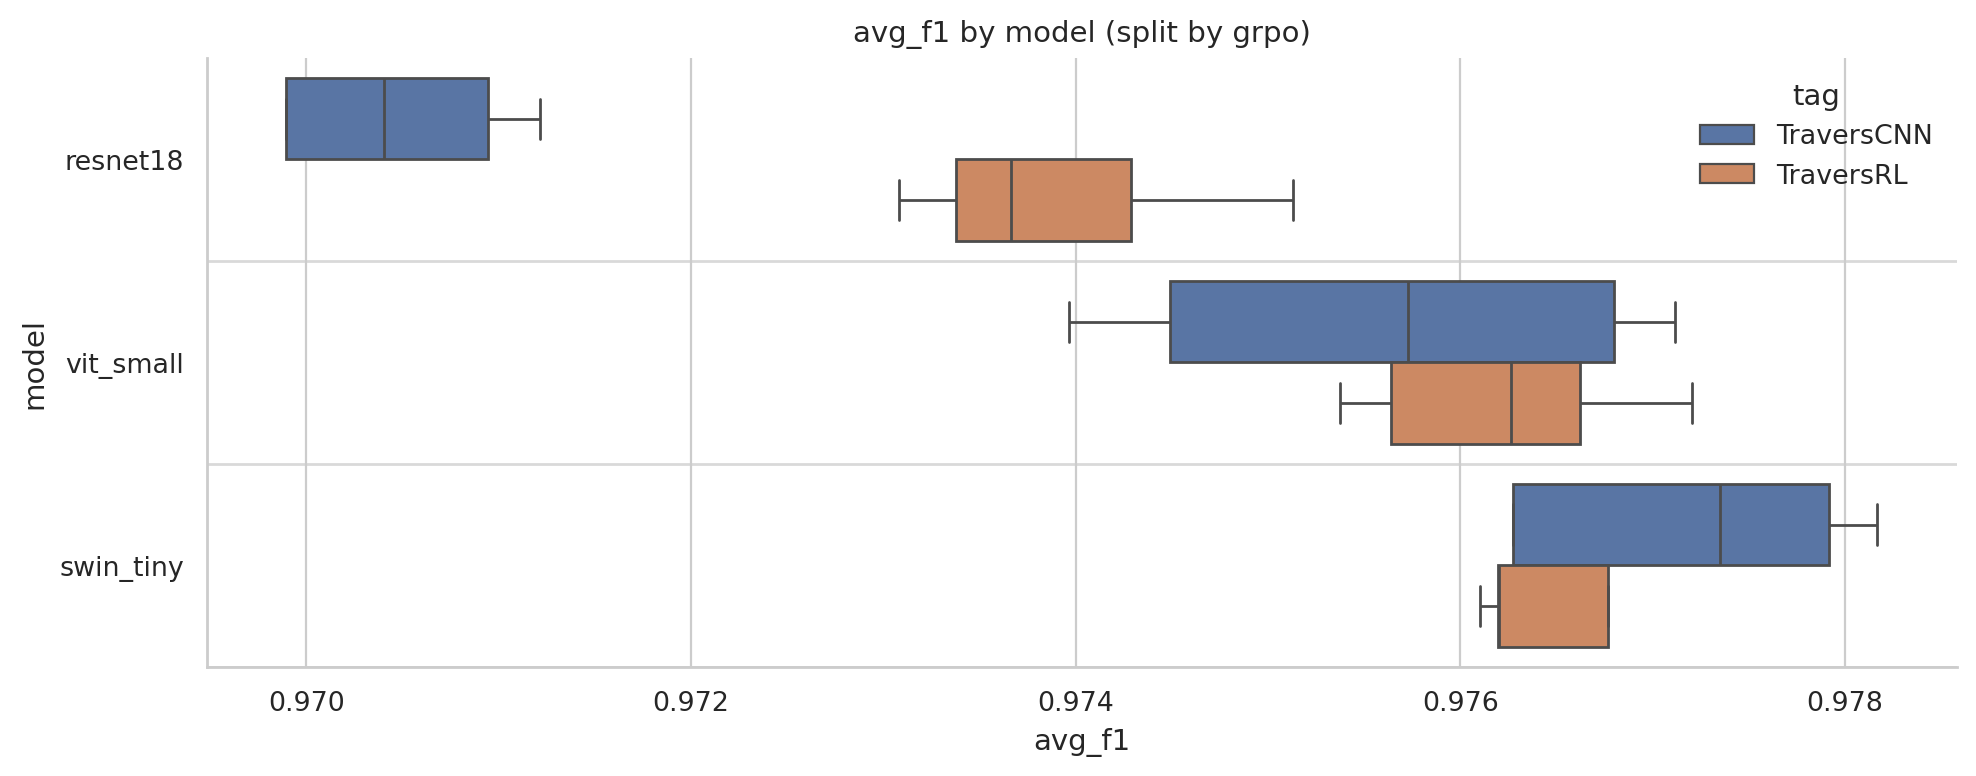

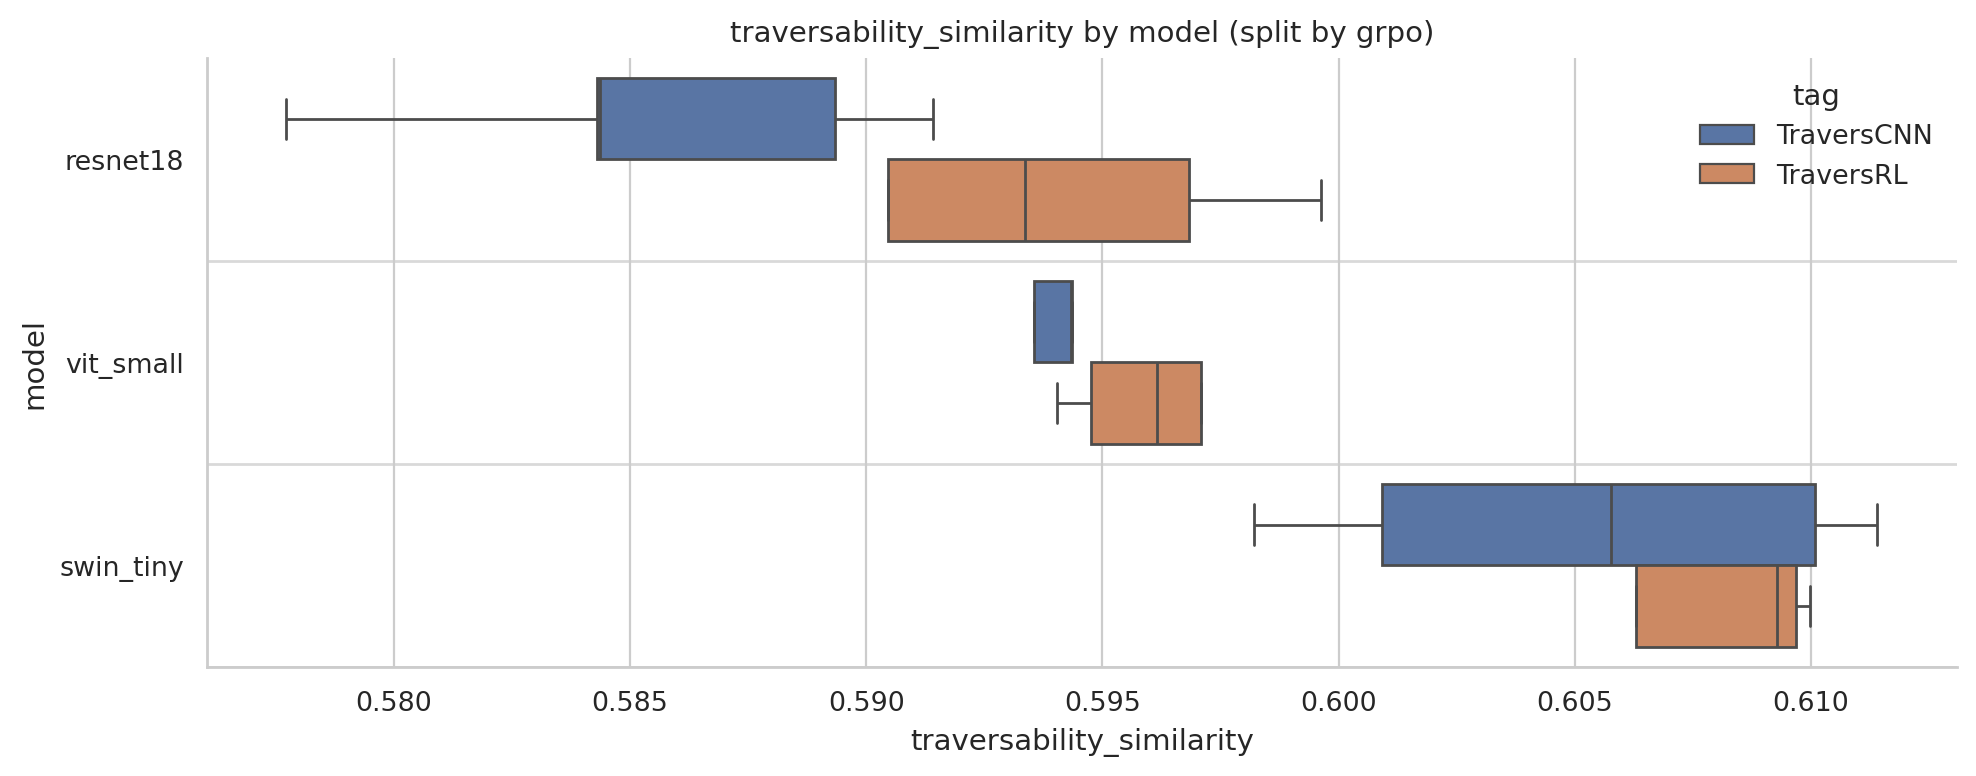

In [4]:
for metric in ["iou", "avg_f1", "traversability_similarity"]:
    plt.figure(figsize=(10, 4))
    model_order = ["resnet18", "vit_small", "swin_tiny"]
    ax = sns.boxplot(
        y="model", x=metric, hue="tag",
        data=results,
        order=model_order,
        showbox=True,
        showfliers=False
    )
    n_models = results["model"].nunique()
    for y in range(1, n_models):
        ax.axhline(y - 0.5, color="0.85", linewidth=1, zorder=0)
    ax.set_title(f"{metric} by model (split by grpo)")
    plt.tight_layout()
    plt.show()

In [4]:
results.groupby(["model", "tag"]).mean().reset_index()[["model", "tag", "iou", "avg_f1", "traversability_similarity"]]

,model,tag,iou,avg_f1,traversability_similarity
0,resnet18,base,0.789849,0.969799,0.585430
1,resnet18,grpo,0.808222,0.973909,0.591714
2,swin_tiny,base,0.811085,0.976623,0.605276
3,swin_tiny,grpo,0.825803,0.976729,0.606924
4,vit_small,base,0.807622,0.975621,0.593477
5,vit_small,grpo,0.823953,0.976221,0.596924


In [5]:
results.groupby(["model", "tag"]).std().reset_index()[["model", "tag", "iou", "avg_f1", "traversability_similarity"]]

,model,tag,iou,avg_f1,traversability_similarity
0,resnet18,base,0.004366,0.001897,0.005310
1,resnet18,grpo,0.001685,0.000815,0.008263
2,swin_tiny,base,0.002889,0.001939,0.005698
3,swin_tiny,grpo,0.001777,0.000960,0.004472
4,vit_small,base,0.003051,0.001383,0.005166
5,vit_small,grpo,0.001943,0.000737,0.003386


In [5]:
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions/evaluation_results_5seeds_epsg:26910_1.csv")
results = results.drop(["dataset", "pred_root"], axis=1)
results.groupby(["model", "tag"]).mean().reset_index()[["model", "tag", "iou", "avg_f1", "traversability_similarity"]].round(3)

,model,tag,iou,avg_f1,traversability_similarity
0,resnet18,base,0.510,0.883,0.586
1,resnet18,grpo,0.539,0.895,0.591
2,resnet18,step,0.540,0.893,0.605
3,swin_tiny,base,0.531,0.898,0.605
4,swin_tiny,grpo,0.559,0.904,0.607
5,tile2net,base,0.231,NaN,0.096
6,vit_small,base,0.525,0.890,0.593
7,vit_small,grpo,0.549,0.896,0.597


In [7]:
results.groupby(["model", "tag"]).std().reset_index()[["model", "tag", "iou", "avg_f1", "traversability_similarity"]].round(3)

,model,tag,iou,avg_f1,traversability_similarity
0,resnet18,base,0.003,0.004,0.005
1,resnet18,grpo,0.001,0.002,0.008
2,swin_tiny,base,0.004,0.004,0.006
3,swin_tiny,grpo,0.002,0.002,0.004
4,vit_small,base,0.003,0.002,0.005
5,vit_small,grpo,0.003,0.003,0.003


### PathwayBench

In [2]:
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions_seattle/evaluation_results_5seeds.csv")
results = results.drop(["dataset", "pred_root"], axis=1)
results = results[results.model != "tile2net"]

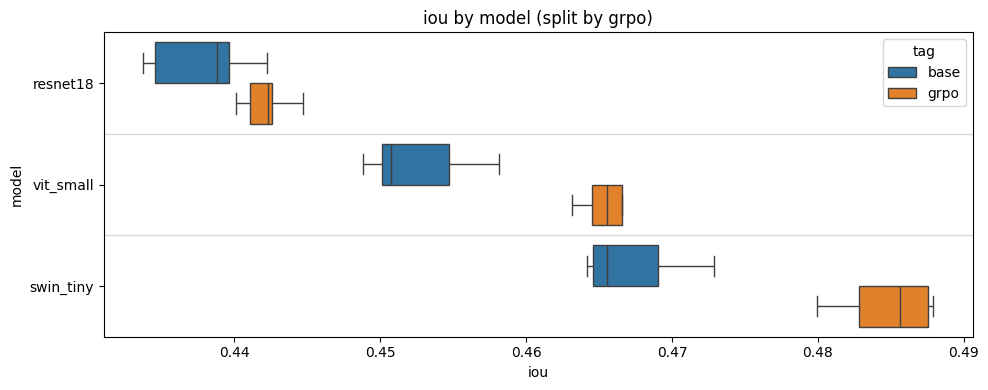

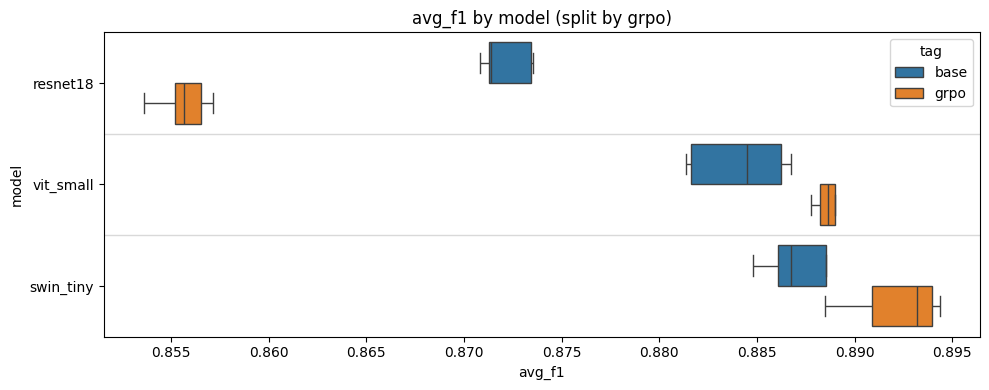

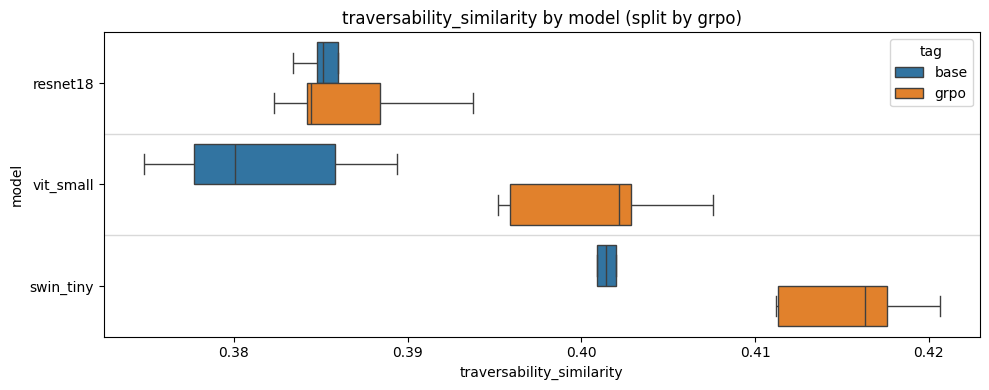

In [7]:
for metric in ["iou", "avg_f1", "traversability_similarity"]:
    plt.figure(figsize=(10, 4))
    model_order = ["resnet18", "vit_small", "swin_tiny"]
    ax = sns.boxplot(
        y="model", x=metric, hue="tag",
        data=results,
        order=model_order,
        showbox=True,
        showfliers=False
    )
    n_models = results["model"].nunique()
    for y in range(1, n_models):
        ax.axhline(y - 0.5, color="0.85", linewidth=1, zorder=0)
    ax.set_title(f"{metric} by model (split by grpo)")
    plt.tight_layout()
    plt.show()

In [5]:
results.groupby(["model", "tag"]).mean().reset_index()[["model", "tag", "iou", "avg_f1", "traversability_similarity"]]

,model,tag,iou,avg_f1,traversability_similarity
0,resnet18,base,0.437797,0.872079,0.385890
1,resnet18,grpo,0.442145,0.855619,0.386631
2,swin_tiny,base,0.467256,0.887781,0.400705
3,swin_tiny,grpo,0.484781,0.892170,0.415410
4,vit_small,base,0.452502,0.884082,0.381567
5,vit_small,grpo,0.466169,0.888916,0.400737


In [8]:
results.groupby(["model", "tag"]).std().reset_index()[["model", "tag", "iou", "avg_f1", "traversability_similarity"]]

,model,tag,iou,avg_f1,traversability_similarity
0,resnet18,base,0.003582,0.001293,0.002542
1,resnet18,grpo,0.001738,0.001365,0.004549
2,swin_tiny,base,0.003683,0.003100,0.003559
3,swin_tiny,grpo,0.003368,0.002471,0.004109
4,vit_small,base,0.003849,0.002508,0.005967
5,vit_small,grpo,0.003027,0.001241,0.005180
